# CyberReplay: Machine Learning-Based Network Intrusion Detection and Attack Analysis

**Shreyansh Krishna** (2026CS05055) · **Aamir Lanker** (2026CS05054) · **Harshith G. D** (2026CS05053) · **Anil Pandey** (2026CS05031) · Course: Machine Learning

Multi-class classification of CIC-IDS2017 network flows into 8 attack families (Track A: scikit-learn / XGBoost),
with a derived binary `is_malicious` output, a traffic-replay dashboard and SHAP explanations.

| Build step | Section |
|---|---|
| 1 Problem + dataset | §0-1 |
| 2 EDA (6 plots) | §2, §3.2 |
| 3 Cleaning | §3 |
| 4 Feature engineering | §4 |
| 5-7 Models, cross-validation, tuning | §5-7 |
| 8-9 Evaluation, best model | §8-9 |
| Report extensions: split overview, ROC-AUC, baseline, over/underfitting | §4.1, §9.1-9.2 |
| 10 Attack patterns (importance, SHAP) | §10 |
| 11-14 Dashboard, replay, interactive visuals, explanations | §11 |
| 15-16 Reproducibility, conclusions | §12-13 |

We keep the implementation in `src/cyberreplay` and use this notebook to run each stage and present its results.
Every stage uses random seed **42**. Figure numbers in this notebook refer to the file numbers in `reports/figures`
(for example, Figure 8 is `08_tuning.png`); the report numbers its figures in reading order instead.

## 0. Setup (Google Colab or local)

We designed this notebook to run in **Google Colab**, our virtual lab, or on a local machine.

On Colab, the first cell clones our public repository
`https://github.com/Shreyansh124/cyberreplay.git` (branch set by `BRANCH`) into `/content/cyberreplay` and installs
the pinned `requirements.txt`, without requiring credentials or manual setup. For local use, it finds the repository root.

When `pip` upgrades NumPy/pandas, the cell restarts the runtime automatically; we then run all cells once more.

In [1]:
# Environment setup: clone the repo + install pinned requirements in Colab; locate the repo locally.
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Shreyansh124/cyberreplay.git"
BRANCH = "main"  # change if the project lives on another branch

if IN_COLAB:
    ROOT = Path("/content/cyberreplay")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "-b", BRANCH, REPO_URL, str(ROOT)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements.txt")], check=True)
    import importlib.metadata as md
    stale = [p for p in ("numpy", "pandas", "scipy") if p in sys.modules
             and sys.modules[p].__version__ != md.version(p)]
    if stale:
        print(f"Upgraded {stale}; restarting the runtime - run all cells again.")
        os.kill(os.getpid(), 9)
else:
    ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()

os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
print("Project root:", ROOT, "| Colab:", IN_COLAB)

Project root: /agent/repos/cyberreplay | Colab: False


**Data location.** We set `DATA_SOURCE = "drive"` when CIC-IDS2017 is already in Google Drive. `DRIVE_DATA_DIR`
must point to the folder containing the day CSVs, either the *TrafficLabelling/GeneratedLabelledFlows* or
*MachineLearningCSV* version; the notebook also searches sub-folders. Setting it to `"download"` retrieves the official
`GeneratedLabelledFlows.zip` (~285 MB) automatically. If no CSVs are present in Drive, we fall back to that download.

With `FORCE_RECOMPUTE = False`, we reuse committed CV / tuning results in `reports/results` and any cached fitted models.
Changing it to `True` recomputes every stage; tuning takes about an hour on 8 CPUs. For a quicker Colab run,
`FINAL_FIT_ROWS` can restrict the final fit to a stratified subset, while the reported results use `None` = full training split.

In [2]:
DATA_SOURCE = "drive"                               # "drive" or "download"
DRIVE_DATA_DIR = "/content/drive/MyDrive/CIC-IDS2017"
FORCE_RECOMPUTE = False
FINAL_FIT_ROWS = None                               # e.g. 500_000 for a quick Colab run

DATA_DIR = ROOT / "data" / "raw"
if IN_COLAB and DATA_SOURCE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    # The day files are named like "Monday-WorkingHours.pcap_ISCX.csv" in both official variants.
    if any(".pcap_ISCX" in p.name for p in Path(DRIVE_DATA_DIR).rglob("*.csv")):
        DATA_DIR = Path(DRIVE_DATA_DIR)
    else:
        print("No CIC-IDS2017 day CSVs found in", DRIVE_DATA_DIR, "- downloading to", DATA_DIR, "instead.")
os.environ["CYBERREPLAY_DATA_DIR"] = str(DATA_DIR)  # must be set before importing cyberreplay

import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from cyberreplay import (clean, config, data, diagnostics, eda, evaluate, explain, features, models, pipeline,
                         replay, tuning, utils)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 40, "display.width", 200, "display.float_format", "{:.4f}".format)
plt.rcParams["figure.dpi"] = 90
np.random.seed(config.SEED)
config.ensure_dirs()
print("Data dir:", config.DATA_DIR, "| seed:", config.SEED, "| n_jobs:", config.N_JOBS)

Data dir: /agent/repos/cyberreplay/data/raw | seed: 42 | n_jobs: 8


## 1. Problem and dataset

**Problem.** Signature-based intrusion detectors can miss new variants and generate too many alerts for analysts.
We train a flow-level ML classifier to identify *which kind* of attack a connection represents: DoS, DDoS, port scan,
botnet, brute force, web attack or a rare intrusion. This lets us organise alerts by family, while the binary
`is_malicious` flag (prediction ≠ BENIGN) supports a simpler allow/deny decision. Because this multi-class task is
heavily imbalanced, our primary metric is **macro F1**, which gives each family equal weight.

**Dataset.** CIC-IDS2017 from the Canadian Institute for Cybersecurity, University of New Brunswick contains five days
(3-7 July 2017) of realistic network traffic from a 25-host testbed with scripted attacks. CICFlowMeter converts the
traffic into bidirectional flows with 80+ statistical features per flow and 15 labels. Its 2.8 M flows, real protocols
and strong imbalance make it a widely used, non-trivial IDS benchmark.

*Source:* official page <https://www.unb.ca/cic/datasets/ids-2017.html>. Since the official download now requires a
registration form, our automated download uses a byte-identical mirror of the official `GeneratedLabelledFlows.zip`
(TrafficLabelling CSVs, which include timestamps) at <https://huggingface.co/datasets/bencorn/CICIDS2017>, with
SHA-256 verification.
*Citation:* I. Sharafaldin, A. H. Lashkari, A. A. Ghorbani, "Toward Generating a New Intrusion Detection Dataset and
Intrusion Traffic Characterization", ICISSP 2018, pp. 108-116.

**Attack families (target).**

| Family | Raw labels |
|---|---|
| BENIGN | BENIGN |
| DoS | DoS Hulk, DoS GoldenEye, DoS slowloris, DoS Slowhttptest |
| DDoS | DDoS (LOIC) |
| PortScan | PortScan |
| Bot | Bot (Ares) |
| Brute Force | FTP-Patator, SSH-Patator |
| Web Attack | Web Attack - Brute Force, XSS, Sql Injection |
| Rare | Infiltration, Heartbleed |

In [3]:
# Load the eight day files (downloads them first if missing). Cached as parquet after the first run.
raw = pipeline.stage_load(config.DATA_DIR, download=True)
display(data.describe_files(config.DATA_DIR))
print(raw.shape)
raw.iloc[:3, :12]  # first columns only; the full frame has 87

[load] 2,830,743 flows x 87 columns


,file,day,size_mb
0,Monday-WorkingHours.pcap_ISCX.csv,Monday,268.6000
1,Tuesday-WorkingHours.pcap_ISCX.csv,Tuesday,174.7000
2,Wednesday-workingHours.pcap_ISCX.csv,Wednesday,285.6000
3,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,Thursday-AM,92.0000
4,Thursday-WorkingHours-Afternoon-Infilteration....,Thursday-PM,108.7000
5,Friday-WorkingHours-Morning.pcap_ISCX.csv,Friday-AM,75.4000
6,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,Friday-PM-PortScan,101.9000
7,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Friday-PM-DDoS,96.1000


(2830743, 87)


,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets
0,192.168.10.5-8.254.250.126-49188-80-6,8.254.250.126,80.0000,192.168.10.5,49188.0000,6.0000,2017-07-03 08:55:58,4.0000,2.0000,0.0000,12.0000,0.0000
1,192.168.10.5-8.254.250.126-49188-80-6,8.254.250.126,80.0000,192.168.10.5,49188.0000,6.0000,2017-07-03 08:55:58,1.0000,2.0000,0.0000,12.0000,0.0000
2,192.168.10.5-8.254.250.126-49188-80-6,8.254.250.126,80.0000,192.168.10.5,49188.0000,6.0000,2017-07-03 08:55:58,1.0000,2.0000,0.0000,12.0000,0.0000


**Observations**

- We loaded 2,830,743 labelled flows from 8 day files (Monday-Friday, 3-7 July 2017), matching the published size of CIC-IDS2017.
- Loading retained 84 original columns after removing the duplicate `Fwd Header Length`, then added 3 metadata columns:
  `day`, `day_order` and `row_order`. We stored measurement columns as float32, which used 1.3 GB in memory.
- We removed 288,602 fully empty CSV lines from the Thursday-morning file while loading. Parsing timestamps day-first
  and correcting the 12-hour clock (e.g. Friday "3:30" = 15:30) produced a consistent 08:42-17:10 capture window.

## 2. Exploratory data analysis

We first normalise labels because the Thursday file stores the en dash in "Web Attack – XSS" as the cp1252 byte
`0x96`. We then map labels into the 8 families while retaining the raw label for analysis.

,flows,share_%
family,,
BENIGN,2273097,80.3004
DoS,252661,8.9256
DDoS,128027,4.5227
PortScan,158930,5.6144
Bot,1966,0.0695
Brute Force,13835,0.4887
Web Attack,2180,0.0770
Rare,47,0.0017


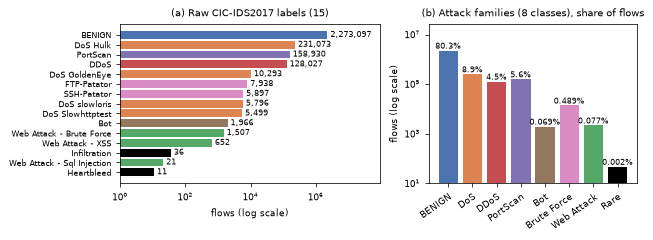

In [4]:
labelled = clean.add_labels(raw)
fam_counts = pd.DataFrame({"flows": labelled[config.TARGET_COL].value_counts()}).reindex(config.CLASS_ORDER)
fam_counts["share_%"] = 100 * fam_counts["flows"] / fam_counts["flows"].sum()
display(fam_counts)
fig = eda.plot_class_distribution(labelled); plt.show()

**Observations**

- The class distribution is highly uneven. BENIGN accounts for 80.3% of flows; only DoS 8.9%, PortScan 5.6% and DDoS
  4.5% are also sizeable. Brute Force (0.49%), Web Attack (0.077%), Bot (0.069%) and Rare (0.002%, 47 flows:
  36 Infiltration + 11 Heartbleed) are much smaller, giving a BENIGN:Rare ratio of ~48,000:1.
- A predictor that always returns BENIGN already reaches 80% accuracy, so accuracy mainly reflects the majority class.
  We therefore use macro F1 as the main metric and apply class weights.
- Combining related labels gives the model more examples: Web Attack - Sql Injection has just 21 flows, whereas its
  grouped Web Attack family has 2,180.

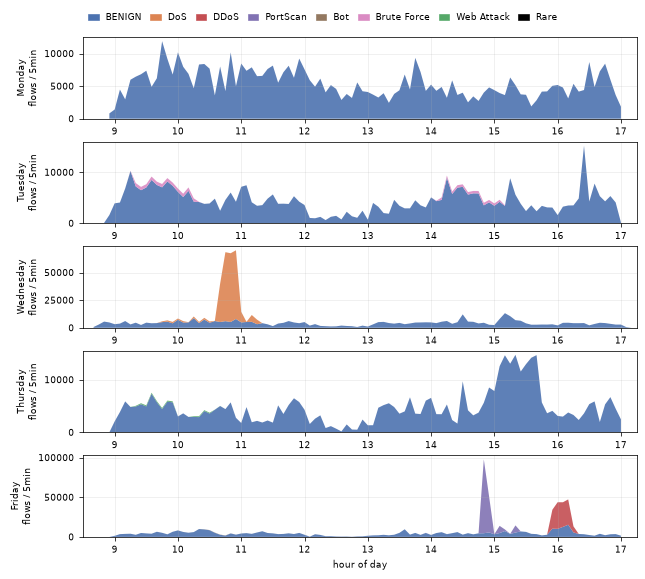

In [5]:
fig = eda.plot_traffic_timeline(labelled); plt.show()

**Observations**

- Monday contains no attacks, while the remaining attacks occur in short bursts: FTP-Patator (Tue ~09:20-10:20),
  SSH-Patator (Tue ~14:00-15:00), DoS Hulk at a peak of ~70k flows per 5 min on Wednesday ~10:45, web attacks on
  Thursday morning, Bot on Friday morning, and PortScan (~95k flows / 5 min at ~14:50) followed by DDoS
  (~15:56-16:16) on Friday afternoon.
- Attack traffic dominates during these bursts, but benign traffic also changes sharply, as seen on Thursday
  15:00-15:40. For that reason, volume by itself is not dependable and we need per-flow features.
- We use these timestamps for the replay in §11. They also reveal a limitation discussed in §13: a random split places
  flows from the same attack burst in both training and test sets.

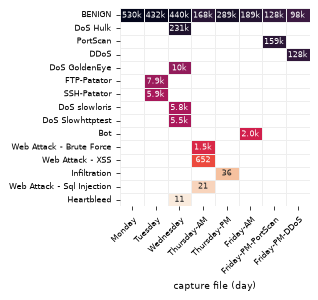

In [6]:
fig = eda.plot_attack_day_matrix(labelled); plt.show()

**Observations**

- Each attack type occurs in exactly **one** capture file: Heartbleed and the DoS family appear on Wednesday,
  Infiltration on Thursday afternoon, and PortScan and DDoS in separate Friday files.
- This prevents meaningful GroupKFold validation by day because a held-out day would remove *all* examples of its attacks
  from training. We instead use StratifiedKFold on the training split (§6).

## 3. Data cleaning

Our row-level cleaning uses no fitted statistics, so we can safely perform it before splitting:
1. We replace `+/-inf` with NaN because rates become infinite when `Flow Duration` = 0. The pipeline
   **median-imputes NaN later**, using a median fitted only on the training split.
2. We clip physically impossible negative durations, IATs and header lengths to 0, but retain the `-1` value in
   `Init_Win_bytes_*` because CICFlowMeter uses it as a sentinel for "no TCP window seen".
3. We remove exact duplicate flows with the same features and family, ignoring identifiers, **before** splitting.
   This prevents one vector from appearing in both train and test.
4. We measure outliers here without deleting them; §3.2 and §4.3 describe their treatment.

,value
rows before cleaning,2830743
+/-inf values -> NaN,4376
NaN values (median-imputed in pipeline),5734
invalid negatives clipped to 0,3545
duplicate rows removed,630963
rows with conflicting labels (kept),622
rows after cleaning,2199780


inf per column: {'Flow Bytes/s': 1509, 'Flow Packets/s': 2867}
negatives clipped per column: {'Flow Duration': 115, 'Flow Bytes/s': 85, 'Flow Packets/s': 115, 'Flow IAT Mean': 115, 'Flow IAT Max': 115, 'Flow IAT Min': 2891, 'Fwd IAT Min': 17, 'Fwd Header Length': 35, 'Bwd Header Length': 22, 'min_seg_size_forward': 35}
duplicates removed per family: {'BENIGN': 409807, 'PortScan': 156972, 'DoS': 58928, 'Brute Force': 4683, 'Bot': 525, 'Web Attack': 37, 'DDoS': 11}


,rows after cleaning
family,
BENIGN,1863290
DoS,193733
DDoS,128016
PortScan,1958
Bot,1441
Brute Force,9152
Web Attack,2143
Rare,47


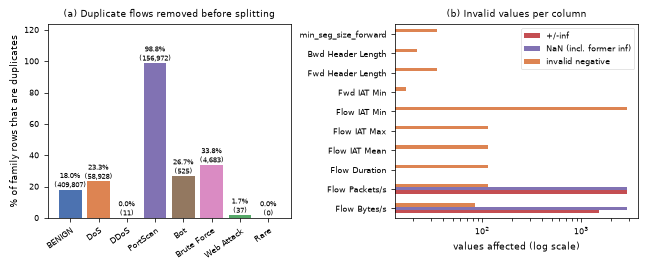

In [7]:
clean_df, report = clean.clean_cached(raw)
display(report.summary())
print("inf per column:", report.inf_counts)
print("negatives clipped per column:", report.negative_counts)
print("duplicates removed per family:", report.duplicates_removed)
display(clean_df[config.TARGET_COL].value_counts().reindex(config.CLASS_ORDER).to_frame("rows after cleaning"))
fig = eda.plot_data_quality(labelled, report); plt.show()

**Observations**

- A `Flow Duration` of 0 produces 4,376 infinite rates: 1,509 in `Flow Bytes/s` and 2,867 in `Flow Packets/s`.
  Together with 1,358 existing NaN entries, this leaves 5,734 missing values, which the pipeline fills using a
  training-set median.
- We clipped 3,545 impossible negative values to 0. Most are in `Flow IAT Min` (2,891, nearly all BENIGN), while the
  -1 sentinel in `Init_Win_bytes_*` (1.0 M and 1.4 M rows) remains because it means "no TCP window observed".
- Before splitting, we removed 630,963 exact duplicate rows (22.3%). PortScan changes most: 98.8% of its 158,930 flows
  are repeated one/two-packet probes, leaving 1,958 unique flows. The corresponding losses are 33.8% for Brute Force,
  26.7% for Bot, 23.3% for DoS and 18.0% for BENIGN. This avoids identical vectors appearing in both train and test and
  overstating performance.
- We retained 622 rows whose feature vector is shared with another family because they represent label noise or
  irreducible ambiguity.
- After cleaning, 2,199,780 flows remain.

### 3.2 EDA on the cleaned flows: feature behaviour, outliers and redundancy

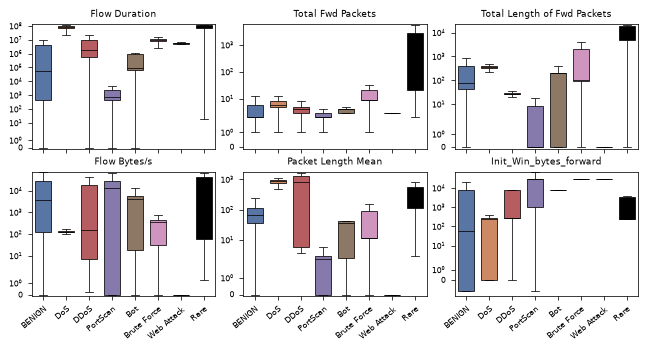

In [8]:
fig = eda.plot_feature_distributions(clean_df); plt.show()

**Observations**

- We found distinct flow profiles for each family. DoS flows stay open for a long time (median `Flow Duration` near
  100 s because of slow-rate attacks) and send large forward payloads. DDoS uses small, uniform forward packets;
  PortScan lasts microseconds, carries no payload and uses 1-2 packets; Web Attack also has almost no forward payload.
  Rare (Infiltration/Heartbleed) flows are both large and long because Heartbleed exfiltrates sizeable memory chunks.
- For Brute Force and Web Attack, `Init_Win_bytes_forward` is nearly constant and acts as a fingerprint of the attack
  tools' TCP stack. This may also mean the models learn tool-specific artefacts instead of general behaviour.
- Feature values span 6-8 orders of magnitude with heavy tails, which supports using a log transform in the linear model.

77 candidate features (identifiers excluded)


,share_rows_with_extreme_value_pct,rows
family,,
BENIGN,1.5300,1863290
DoS,3.5100,193733
DDoS,1.1300,128016
PortScan,0.7200,1958
Bot,3.4000,1441
Brute Force,0.0900,9152
Web Attack,0.7000,2143
Rare,48.9400,47


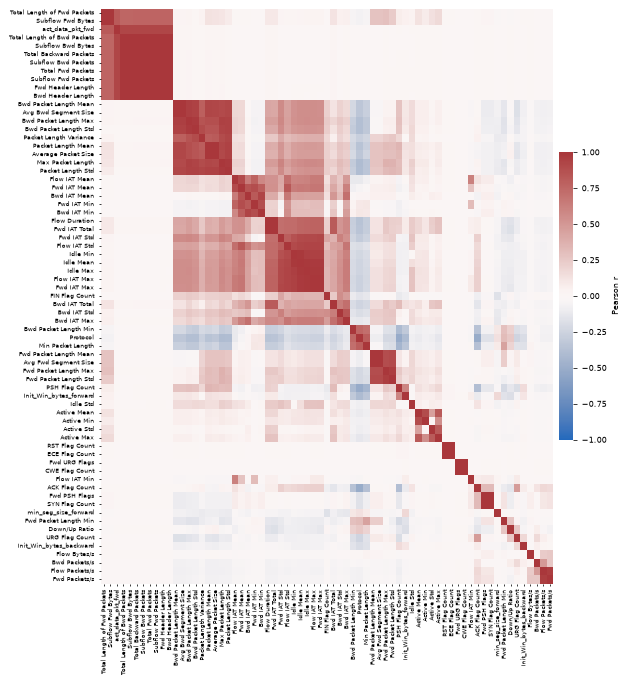

50 feature pairs with |r| > 0.95


,feature_a,feature_b,r
0,Total Length of Fwd Packets,Subflow Fwd Bytes,1.0000
1,Total Backward Packets,Subflow Bwd Packets,1.0000
2,RST Flag Count,ECE Flag Count,1.0000
3,Fwd URG Flags,CWE Flag Count,1.0000
4,Fwd PSH Flags,SYN Flag Count,1.0000
5,Fwd Packet Length Mean,Avg Fwd Segment Size,1.0000
6,Bwd Packet Length Mean,Avg Bwd Segment Size,1.0000
7,Total Fwd Packets,Subflow Fwd Packets,1.0000
8,Total Length of Bwd Packets,Subflow Bwd Bytes,1.0000
9,Subflow Bwd Packets,Bwd Header Length,0.9999


In [9]:
candidates = clean.feature_columns(clean_df)
print(len(candidates), "candidate features (identifiers excluded)")
display(clean.outlier_summary(clean_df, candidates))
fig, corr_pairs = eda.plot_correlation_heatmap(clean_df, candidates); plt.show()
print(len(corr_pairs), "feature pairs with |r| >", config.CORRELATION_THRESHOLD)
display(corr_pairs.head(10))

**Observations**

- Values above the global 99.9th percentile occur in 1.5% of BENIGN rows but **48.9% of Rare rows**. Extreme values
  therefore carry useful information for the rarest attacks, so we do not delete these rows. Only Logistic Regression
  caps values at the training 99.9th percentile, preventing extreme magnitudes from distorting its scaled linear fit;
  tree models receive the raw values after imputation.
- We identified 50 feature pairs with |r| > 0.95, including 9 exact copies with r = 1.0, such as
  `Subflow Fwd Bytes` = `Total Length of Fwd Packets` and `SYN Flag Count` = `Fwd PSH Flags`. The clustered heatmap
  groups redundant packet counts / header lengths, packet-size statistics and IAT / idle times, which supports applying
  the correlation filter.

## 4. Feature engineering and leakage control

* **Target encoding:** We encode families as integer codes 0-7 (`BENIGN` = 0) and derive binary `is_malicious`
  from the predictions.
* **Split:** We make a stratified 80/20 train/test split of de-duplicated data using seed 42, then leave the test
  split untouched until §8.
* **Identifiers excluded:** We remove Flow ID, Source/Destination IP, Source/Destination Port and Timestamp.
* **Feature selection (train only):** We apply a variance filter, then a greedy correlation filter (|r| > 0.95),
  followed by class-weighted Random Forest importance that retains 99% cumulative importance.
* **Preprocessing inside sklearn Pipelines:** Every model performs column selection and median imputation. Logistic
  Regression also applies 99.9th-percentile capping, signed `log1p` and `StandardScaler`. We fit each operation only
  on training folds.

In [10]:
train, test = features.split_train_test(clean_df)
split_counts = pd.DataFrame({"train": train[config.TARGET_COL].value_counts(),
                             "test": test[config.TARGET_COL].value_counts()}).reindex(config.CLASS_ORDER)
display(split_counts)
del raw, labelled  # free memory
sel = pipeline.stage_select(train, candidates, force=FORCE_RECOMPUTE)
FEATURES = sel["selected"]
print(sel["counts"])
print("Constant (dropped):", sel["constant"])
print("Correlated (dropped):", sel["correlated_dropped"])
print("Low importance (dropped):", sel["low_importance_dropped"])
print(f"\n{len(FEATURES)} selected features:", FEATURES)

,train,test
family,,
BENIGN,1490632,372658
DoS,154986,38747
DDoS,102413,25603
PortScan,1566,392
Bot,1153,288
Brute Force,7322,1830
Web Attack,1714,429
Rare,38,9


{'candidates': 77, 'after_variance': 69, 'after_correlation': 44, 'after_importance': 37}
Constant (dropped): ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
Correlated (dropped): ['Total Backward Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Std', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Fwd IAT Total', 'Fwd IAT Max', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Packet Length Std', 'SYN Flag Count', 'CWE Flag Count', 'ECE Flag Count', 'Average Packet Size', 'Avg Fwd Segment Size', 'Avg Bwd Segment Size', 'Subflow Fwd Packets', 'Subflow Fwd Bytes', 'Subflow Bwd Packets', 'Subflow Bwd Bytes', 'act_data_pkt_fwd', 'Idle Mean', 'Idle Max', 'Idle Min']
Low importance (dropped): ['Active Min', 'URG Flag Count', 'FIN Flag Count', 'Idle Std', 'Active Std', 'RST Flag Count', 'Fwd URG Flags']

37 selected features: ['Protocol', 'Flow Dur

### 4.1 The train/test split per family

We show how many flows of each family land in each part of the split. The figure uses a log scale because BENIGN has
almost 40,000 times more unique flows than Rare.

,family,raw_labels,meaning,raw_flows,unique_flows,train,test,test_share
0,BENIGN,BENIGN,"normal traffic of the lab users (web, e-mail, ...",2273097,1863290,1490632,372658,0.2000
1,DoS,"DoS Hulk, DoS GoldenEye, DoS slowloris, DoS Sl...",one host floods or starves the web server,252661,193733,154986,38747,0.2000
2,DDoS,DDoS,many hosts flood the web server (LOIC),128027,128016,102413,25603,0.2000
3,PortScan,PortScan,Nmap probes that look for open ports,158930,1958,1566,392,0.2002
4,Bot,Bot,Ares botnet hosts talking to their C&C server,1966,1441,1153,288,0.1999
5,Brute Force,"FTP-Patator, SSH-Patator",password guessing on FTP and SSH (Patator),13835,9152,7322,1830,0.2000
6,Web Attack,"Web Attack - Brute Force, Web Attack - XSS, We...","login guessing, XSS and SQL injection on a web...",2180,2143,1714,429,0.2002
7,Rare,"Infiltration, Heartbleed",internal infiltration and the Heartbleed memor...,47,47,38,9,0.1915
8,Total,,,2830743,2199780,1759824,439956,0.2000


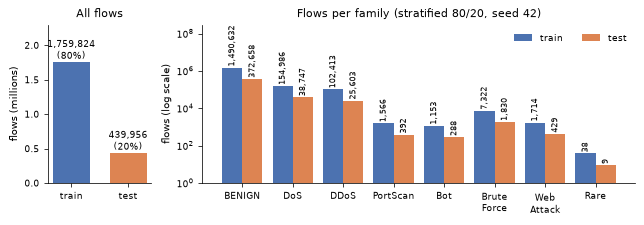

In [11]:
raw_counts = clean_df[config.TARGET_COL].value_counts().add(pd.Series(report.duplicates_removed), fill_value=0)
split_table = diagnostics.split_table(train, test, raw_counts)
display(split_table)
fig = diagnostics.plot_split(split_table); plt.show()

**Observations**

- The stratified 80/20 split of the 2,199,780 de-duplicated flows gives 1,759,824 training and 439,956 test flows. Every
  family keeps the same share in both parts (test share 0.19-0.20), so even Rare has 38 training and 9 test flows.
- De-duplication changes the family sizes a lot: PortScan falls from 158,930 raw flows to 1,958 unique ones, while DDoS
  and Rare lose almost nothing. The test split therefore holds only 392 PortScan, 288 Bot and 9 Rare flows, which is why
  the per-class scores of these families move in large steps.

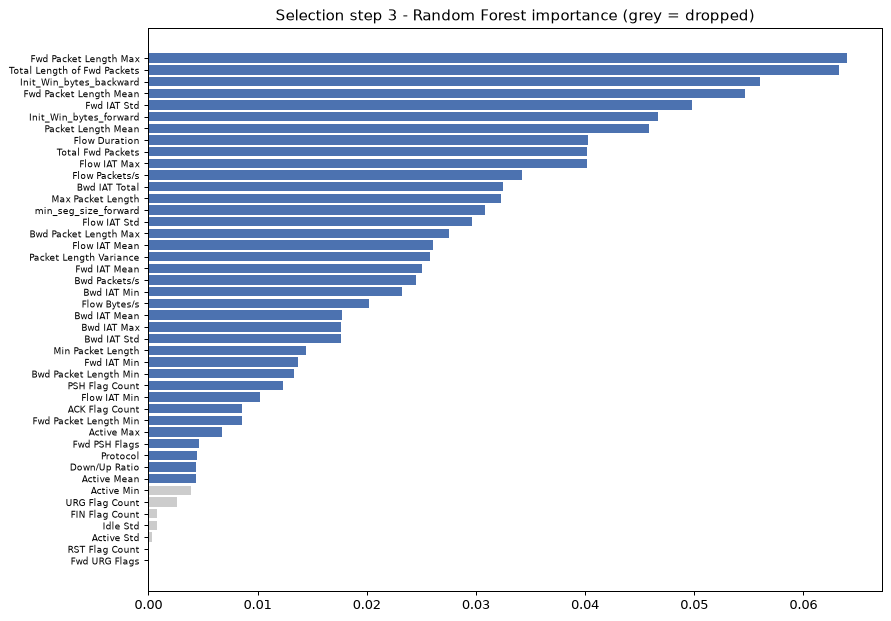

In [12]:
imp = pd.read_csv(config.RESULTS_DIR / "selection_importance.csv")
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(imp["feature"][::-1], imp["importance"][::-1], color=np.where(imp["selected"][::-1], "#4c72b0", "#cccccc"))
ax.set_title("Selection step 3 - Random Forest importance (grey = dropped)")
ax.tick_params(axis="y", labelsize=7); plt.tight_layout(); plt.show()

**Observations**

- We began with 77 candidates and retained 69 after removing 8 constant columns; all bulk-rate features and the Bwd
  PSH/URG flags are always 0. The correlation filter then retained 44 by dropping 25 redundant twins while keeping each
  pair's basic statistic. Finally, retaining 99% of cumulative Random Forest importance produced **37** features after
  7 near-useless flags/statistics were removed.
- Forward payload size (`Fwd Packet Length Max`, `Total Length of Fwd Packets`), TCP handshake information
  (`Init_Win_bytes_backward/forward`, `min_seg_size_forward`) and timing (`Fwd IAT Std`, `Flow Duration`) contribute the
  strongest features.
- We fitted all three filters only on the training split, leaving the test split with no role in feature selection.

In [13]:
# The preprocessing pipelines (fitted later on training data only).
print(models.build_pipeline("LogisticRegression", FEATURES))
print(models.build_pipeline("XGBoost", FEATURES))

Pipeline(steps=[('select',
                 ColumnSelector(columns=['Protocol', 'Flow Duration',
                                         'Total Fwd Packets',
                                         'Total Length of Fwd Packets',
                                         'Fwd Packet Length Max',
                                         'Fwd Packet Length Min',
                                         'Fwd Packet Length Mean',
                                         'Bwd Packet Length Max',
                                         'Bwd Packet Length Min',
                                         'Flow Bytes/s', 'Flow Packets/s',
                                         'Flow IAT Mean', 'Flow IAT Std',
                                         'Flow IAT Max', 'Flow IAT Min',
                                         'Fwd IAT Mean', 'Fwd IAT Std',
                                         'Fwd IAT Min', 'Bwd...
                                         'Fwd PSH Flags', 'Bwd Packets/s',
     

## 5. Models

We compare four Track A models, each paired with the preprocessing described above:

| Model | Why it is included | Imbalance handling |
|---|---|---|
| Logistic Regression (multinomial, lbfgs) | interpretable linear reference | class-balancing sample weights |
| Decision Tree (CART) | fast non-linear decision rules | class-balancing sample weights |
| Random Forest | averaged trees that resist noise | class-balancing sample weights |
| XGBoost (hist) | boosted trees suited to tabular data | class-balancing sample weights |

Each estimator calculates weights inside `fit` from its own training rows, keeping every CV fold free of leakage.
We tune weight strength between `balanced` (n / (k·count)) and its square root `sqrt`.

**Tuning sample.** For CV and tuning, we take a stratified 500k-row sample from the *training* split. It includes
**all** rows from each family with fewer than 50k training rows and proportionally samples BENIGN / DoS / DDoS.

In [14]:
tune_df = features.stratified_sample(train, config.TUNING_SAMPLE_SIZE)
display(pd.DataFrame({"tuning sample": tune_df[config.TARGET_COL].value_counts(),
                      "full train": train[config.TARGET_COL].value_counts()}).reindex(config.CLASS_ORDER))

,tuning sample,full train
family,,
BENIGN,416318,1490632
DoS,43286,154986
DDoS,28603,102413
PortScan,1566,1566
Bot,1153,1153
Brute Force,7322,7322
Web Attack,1714,1714
Rare,38,38


## 6. Cross-validation (StratifiedKFold, training data only)

We first evaluate default hyperparameters on the tuning sample with
5-fold `StratifiedKFold(shuffle=True, random_state=42)`.

*Why not GroupKFold by capture day?* Figure 3 shows that each attack type was recorded on exactly one day. If we held
out a day, its attack would disappear from the training folds; for example, all DDoS occurs on Friday afternoon.
The model could not learn that class, and the score would test "unseen attack type" detection rather than
classification. Stratification keeps every family represented in every fold.

model,DecisionTree,LogisticRegression,RandomForest,XGBoost
fold,,,,
1,0.9473,0.5353,0.9380,0.9575
2,0.9450,0.5349,0.9535,0.9575
3,0.9251,0.5309,0.9484,0.9509
4,0.9720,0.5350,0.9720,0.9651
5,0.9346,0.5317,0.9560,0.9684


f1_macro        accuracy        recall_macro        precision_macro        fit_time_s       
                       mean    std     mean    std         mean    std            mean    std       mean    std
model                                                                                                          
LogisticRegression   0.5336 0.0021   0.8946 0.0022       0.9536 0.0106          0.4714 0.0033    38.5505 0.8774
DecisionTree         0.9448 0.0176   0.9981 0.0002       0.9374 0.0191          0.9536 0.0161     7.4458 0.3687
RandomForest         0.9536 0.0124   0.9978 0.0003       0.9543 0.0120          0.9590 0.0182     5.4342 0.0904
XGBoost              0.9599 0.0069   0.9984 0.0001       0.9690 0.0138          0.9575 0.0102     5.5870 0.5483

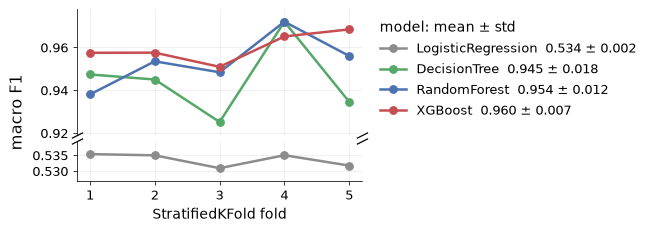

In [15]:
cv_folds = pipeline.stage_cv(tune_df, FEATURES, force=FORCE_RECOMPUTE)
display(cv_folds.pivot(index="fold", columns="model", values="f1_macro"))
display(cv_folds.groupby("model", sort=False)[["f1_macro", "accuracy", "recall_macro", "precision_macro",
                                               "fit_time_s"]].agg(["mean", "std"]))
fig = evaluate.plot_cv_folds(cv_folds); plt.show()

**Observations**

- With default parameters, 5-fold CV gives macro F1 scores of XGBoost 0.960 ± 0.007, Random Forest 0.954 ± 0.012,
  Decision Tree 0.945 ± 0.018 and Logistic Regression 0.534 ± 0.002.
- Tree-model results remain consistent between folds, with accuracy ≥ 0.998 in every fold. Their macro F1 variation
  (± 0.007-0.018) comes mainly from the smallest classes because each validation fold contains only ~8 Rare and
  ~230 Bot rows.
- Fully balanced Logistic Regression reaches macro recall 0.95 but only macro precision 0.47. Large weights for tiny
  classes move its linear boundaries far into BENIGN traffic and create many false alarms, so we tune the weight strength.

## 7. Hyperparameter tuning (RandomizedSearchCV, scoring = f1_macro)

We run 3-fold stratified RandomizedSearchCV on the tuning sample with these search spaces:

In [16]:
for name in config.MODEL_NAMES:
    space = {k.replace("model__", ""): (v if isinstance(v, list) else f"{v.dist.name}{v.args}")
             for k, v in models.search_space(name).items()}
    print(f"{name} (n_iter={models.N_ITER[name]}):", space)

LogisticRegression (n_iter=10): {'C': 'loguniform(0.01, 1000.0)', 'tol': [0.0001, 0.001], 'class_weighting': ['balanced', 'sqrt']}
DecisionTree (n_iter=30): {'criterion': ['gini', 'entropy'], 'max_depth': [None, 15, 20, 30, 40], 'min_samples_split': 'randint(2, 21)', 'min_samples_leaf': 'randint(1, 11)', 'max_features': [None, 'sqrt', 0.5, 0.8], 'class_weighting': ['balanced', 'sqrt']}
RandomForest (n_iter=20): {'n_estimators': [100, 150, 200], 'max_depth': [None, 20, 30, 40], 'min_samples_leaf': [1, 2, 4], 'max_features': ['sqrt', 0.3, 0.5], 'class_weighting': ['balanced', 'sqrt'], 'criterion': ['gini', 'entropy']}
XGBoost (n_iter=20): {'n_estimators': [200, 300, 400], 'max_depth': [6, 8, 10, 12], 'learning_rate': 'loguniform(0.03, 0.3)', 'subsample': 'uniform(0.7, 0.3)', 'colsample_bytree': 'uniform(0.6, 0.4)', 'min_child_weight': [1, 3, 5], 'reg_lambda': [0.5, 1.0, 2.0, 5.0], 'class_weighting': ['balanced', 'sqrt']}


,cv5_default_f1_macro,cv3_tuned_f1_macro,tuned_fold_scores,best_params,gain
model,,,,,
LogisticRegression,0.5336,0.7899,"0.7904, 0.7834, 0.7960","C=10.13, class_weighting=sqrt, tol=0.0001",0.2563
DecisionTree,0.9448,0.9494,"0.9559, 0.9229, 0.9693","class_weighting=balanced, criterion=entropy, m...",0.0046
RandomForest,0.9536,0.9630,"0.9608, 0.9536, 0.9745","n_estimators=150, min_samples_leaf=1, max_feat...",0.0094
XGBoost,0.9599,0.9660,"0.9584, 0.9657, 0.9738","class_weighting=balanced, colsample_bytree=0.6...",0.0061


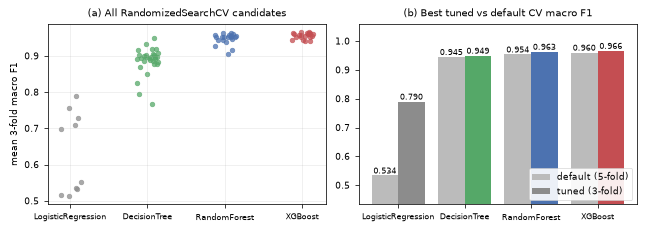

,rank_test_score,mean_test_score,std_test_score,mean_fit_time,split0_test_score,split1_test_score,split2_test_score,class_weighting,colsample_bytree,learning_rate,max_depth,min_child_weight,n_estimators,reg_lambda,subsample
0,1,0.9660,0.0063,14.2908,0.9584,0.9657,0.9738,balanced,0.6807,0.2360,6,1,300,0.5000,0.7748
1,2,0.9645,0.0039,17.1940,0.9592,0.9661,0.9683,balanced,0.6564,0.1902,6,1,400,0.5000,0.9317
2,3,0.9638,0.0072,17.6231,0.9540,0.9708,0.9667,sqrt,0.7174,0.0310,10,1,400,2.0000,0.9314
3,4,0.9622,0.0038,9.2956,0.9604,0.9587,0.9675,sqrt,0.8989,0.1039,12,3,200,5.0000,0.8821
4,5,0.9622,0.0047,30.2404,0.9556,0.9648,0.9661,sqrt,0.6931,0.0370,8,5,400,5.0000,0.8777


In [17]:
tuned = pipeline.stage_tune(tune_df, FEATURES, force=FORCE_RECOMPUTE)
tune_summary = tuning.tuning_summary(tuned, cv_folds)
display(tune_summary)
fig = evaluate.plot_tuning(tune_summary, {n: r["cv_results"] for n, r in tuned.items()}); plt.show()
display(tuned["XGBoost"]["cv_results"].head(5))

**Observations**

- Tuning improves all four models, with the largest change for Logistic Regression: 0.534 to **0.790** using C ≈ 10
  and square-root class weights. Figure 8 separates its candidates into fully balanced (0.51-0.55) and square-root
  weighting (0.70-0.79) groups, showing that weight strength matters much more than C.
- The tree models retain fully balanced weights and improve by smaller amounts. Decision Tree moves from 0.945 to 0.949
  (entropy, unlimited depth, `min_samples_leaf=2`, `max_features=0.8`); Random Forest moves from 0.954 to 0.963
  (150 trees, `max_depth=20`, `max_features=0.5`, entropy); and XGBoost moves from 0.960 to 0.966
  (300 rounds, depth 6, learning rate 0.24, row/column subsampling 0.77/0.68).
- Since the best XGBoost and Random Forest candidates differ by only 0.003 in CV, we use the test split and the extra
  criteria in §9 for the final decision.

## 8. Final training on the full training split and test evaluation

We refit every tuned pipeline on the **full** training split of 1.76 M flows, then evaluate it once on the untouched
test split of 440k flows. We record training time as wall-clock fit time and inference time as `predict` over the
complete test split.
Wall-clock times depend on the machine and its load, so a re-run shows its own measurements; the observations below
quote the reported run.

In [18]:
fit_train = train if FINAL_FIT_ROWS is None else features.stratified_sample(train, FINAL_FIT_ROWS)
fitted = pipeline.stage_fit(fit_train, FEATURES, tuned, force=FORCE_RECOMPUTE)
results, comparison = pipeline.stage_evaluate(fitted, test, FEATURES)
display(comparison[["accuracy", "precision_macro", "recall_macro", "f1_macro", "f1_macro_excl_rare",
                    "minority_recall", "benign_fpr",
                    "train_time_s", "inference_time_s", "inference_us_per_flow"]])

                    f1_macro  ci95_low  ci95_high  diff_to_best_mean  share_best_higher
model                                                                                  
LogisticRegression    0.7147    0.7051     0.7258            -0.2025             1.0000
DecisionTree          0.8950    0.8475     0.9232            -0.0262             1.0000
RandomForest          0.9206    0.8643     0.9473             0.0000             0.0000
XGBoost               0.9117    0.8570     0.9425            -0.0092             0.9900


,accuracy,precision_macro,recall_macro,f1_macro,f1_macro_excl_rare,minority_recall,benign_fpr,train_time_s,inference_time_s,inference_us_per_flow
model,,,,,,,,,,
LogisticRegression,0.9828,0.6497,0.8804,0.7147,0.8080,0.8187,0.0164,215.8413,0.3075,0.6990
DecisionTree,0.9988,0.8781,0.9140,0.8950,0.9477,0.8629,0.0010,34.8806,0.1039,0.2361
RandomForest,0.9989,0.9360,0.9329,0.9206,0.9500,0.8929,0.0011,103.9984,0.5420,1.2320
XGBoost,0.9990,0.9111,0.9296,0.9117,0.9467,0.8876,0.0011,72.5204,1.3792,3.1348


In [19]:
y_test = features.encode_target(test[config.TARGET_COL])
for name, r in results.items():
    print(f"===== {name} =====")
    print(evaluate.classification_text(y_test, r["y_pred"]))

===== LogisticRegression =====
              precision    recall  f1-score   support

      BENIGN     0.9964    0.9836    0.9900    372658
         DoS     0.8960    0.9685    0.9308     38747
        DDoS     0.9870    0.9981    0.9925     25603
    PortScan     0.5071    0.9158    0.6527       392
         Bot     0.3053    0.8576    0.4503       288
 Brute Force     0.8711    0.9639    0.9152      1830
  Web Attack     0.6015    0.9114    0.7247       429
        Rare     0.0328    0.4444    0.0611         9

    accuracy                         0.9828    439956
   macro avg     0.6497    0.8804    0.7147    439956
weighted avg     0.9852    0.9828    0.9837    439956

===== DecisionTree =====
              precision    recall  f1-score   support

      BENIGN     0.9997    0.9990    0.9993    372658
         DoS     0.9950    0.9986    0.9968     38747
        DDoS     0.9990    0.9997    0.9993     25603
    PortScan     0.8981    0.9668    0.9312       392
         Bot     0.678

              precision    recall  f1-score   support

      BENIGN     0.9999    0.9989    0.9994    372658
         DoS     0.9957    0.9997    0.9977     38747
        DDoS     0.9991    0.9997    0.9994     25603
    PortScan     0.9358    0.9668    0.9511       392
         Bot     0.5774    0.9583    0.7206       288
 Brute Force     0.9940    0.9956    0.9948      1830
  Web Attack     0.9860    0.9883    0.9872       429
        Rare     1.0000    0.5556    0.7143         9

    accuracy                         0.9989    439956
   macro avg     0.9360    0.9329    0.9206    439956
weighted avg     0.9991    0.9989    0.9990    439956

===== XGBoost =====
              precision    recall  f1-score   support

      BENIGN     0.9999    0.9989    0.9994    372658
         DoS     0.9962    0.9998    0.9980     38747
        DDoS     0.9993    0.9997    0.9995     25603
    PortScan     0.9272    0.9745    0.9502       392
         Bot     0.5690    0.9167    0.7021       288
 Bru

**Observations**

- On the untouched test split of 439,956 flows, Random Forest records the highest macro F1 (**0.921**), ahead of XGBoost
  (0.912), Decision Tree (0.895) and Logistic Regression (0.715). All tree models have accuracy ≥ 0.998, which provides
  little information for this imbalanced problem.
- Test macro F1 falls below CV macro F1 (~0.96) for two main reasons. First, (1) the test split preserves the true BENIGN
  share (85%), while the tuning sample thins BENIGN, reducing small-class precision (Bot precision 0.57-0.68). Second,
  (2) Rare has only 9 test flows, so one miss changes that class by ~0.1 F1. Excluding Rare leaves the tree models within
  0.004 of one another at macro F1 0.947-0.950.
- The larger BENIGN, DoS, DDoS and Brute Force families reach F1 ≥ 0.995. Bot (F1 0.70-0.74), Rare (0.53-0.71), and
  PortScan and Web Attack for the linear model remain the difficult cases.
- Fitting 1.76 M flows takes 32 s for DT, 62 s for XGB, 92 s for RF and 231 s for LogReg. Every model predicts the
  complete 440k-flow test set in well under 2 s (≈ 0.2-3 µs per flow), comfortably within real-time requirements.

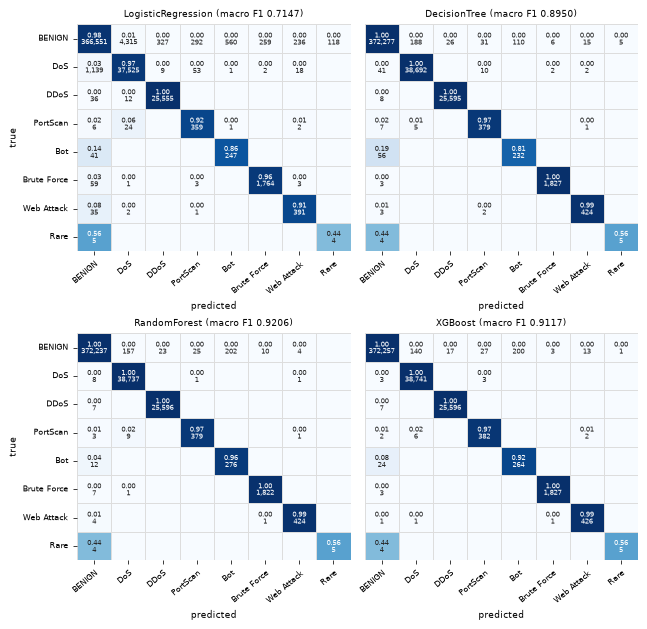

In [20]:
fig = evaluate.plot_confusion_matrices(results); plt.show()

**Observations**

- Most mistakes involve BENIGN. Random Forest labels 157 BENIGN flows as DoS and 202 as Bot, while it misses 4 of the
  9 Rare flows (all Infiltration) and 12 of 288 Bot flows as BENIGN. Confusion directly between attack families is rare.
- Of the 202 BENIGN flows labelled as Bot, 158 contact 205.174.165.73:8080, the Ares C&C server and port used by every
  labelled Bot flow, but outside the labelled Bot period. These are likely unlabelled bot beacons, consistent with the
  CIC-IDS2017 labelling issues documented by Engelen et al., 2021, although we still count them as errors.
- Every tree model detects both Heartbleed flows. Infiltration is hardest because traffic after the initial compromise
  resembles ordinary activity from an internal host.
- Logistic Regression produces a clearly poorer matrix, with 1.6% of BENIGN flows becoming false alarms distributed
  across every attack family.

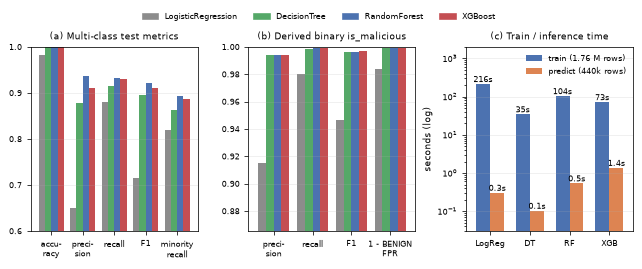

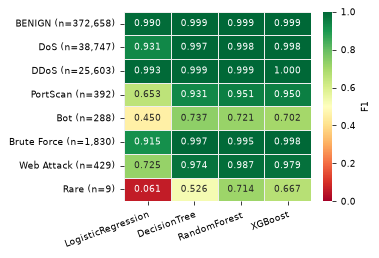

,binary_accuracy,binary_precision,binary_recall,binary_f1,benign_fpr
model,,,,,
LogisticRegression,0.9831,0.9153,0.9804,0.9467,0.0164
DecisionTree,0.9989,0.9944,0.9982,0.9963,0.0010
RandomForest,0.9989,0.9938,0.9993,0.9965,0.0011
XGBoost,0.9990,0.9941,0.9993,0.9967,0.0011


In [21]:
fig = evaluate.plot_comparison(comparison); plt.show()
fig = evaluate.plot_per_class_f1(results); plt.show()
display(comparison[["binary_accuracy", "binary_precision", "binary_recall", "binary_f1", "benign_fpr"]])

**Observations**

- For the binary `is_malicious` output derived from multi-class predictions, the three tree models perform almost the
  same: F1 0.996-0.997, recall 0.998-0.999 and a BENIGN false-positive rate of 0.10-0.11%, or ≈ 400 false alarms among
  373k benign flows. Logistic Regression gives F1 0.947 and a 1.64% false-positive rate, producing 15x more false alarms.
- Figure 11's per-class F1 separates the models more clearly. Random Forest leads on PortScan, Web Attack and Rare;
  Decision Tree leads on Bot; and XGBoost leads on DoS, DDoS and Brute Force. Except for Rare, the tree models stay
  within 0.04 on each class.
- Inference is fastest for Decision Tree at ~0.2 µs/flow, followed by Random Forest at ~1.1 µs/flow and XGBoost at
  ~3 µs/flow.

## 9. Choosing the final model

In [22]:
display(pd.read_csv(config.RESULTS_DIR / "test_bootstrap_ci.csv", index_col=0))
best, why = evaluate.choose_best(comparison)
print(why)
pipeline.stage_save_best(best, why, fitted, comparison, train, FEATURES, tuned)
print(f"Saved {config.BEST_MODEL_PATH} ({config.BEST_MODEL_PATH.stat().st_size / 1e6:.1f} MB)")

,f1_macro,ci95_low,ci95_high,diff_to_best_mean,share_best_higher
model,,,,,
LogisticRegression,0.7147,0.7051,0.7258,-0.2025,1.0000
DecisionTree,0.8950,0.8475,0.9232,-0.0262,1.0000
RandomForest,0.9206,0.8643,0.9473,0.0000,0.0000
XGBoost,0.9117,0.8570,0.9425,-0.0092,0.9900


RandomForest has macro F1 0.9206 (next best 0.9117), minority-class recall 0.8929, BENIGN false-positive rate 0.1130%, trains in 104s and predicts at 1.23 us/flow.


[best] RandomForest saved (5.68 MB): RandomForest has macro F1 0.9206 (next best 0.9117), minority-class recall 0.8929, BENIGN false-positive rate 0.1130%, trains in 104s and predicts at 1.23 us/flow.
Saved /agent/repos/cyberreplay/models/best_model.joblib (5.7 MB)


**Observations**

- **We select Random Forest as the final model.** It achieves the highest test macro F1 (0.921, 95% bootstrap CI
  0.864-0.947), the highest macro F1 without Rare (0.950), and the best minority-class recall (0.893 across PortScan,
  Bot, Brute Force, Web Attack, Rare). Its BENIGN false-positive rate is 0.11%, equal to XGBoost; training takes
  ~1.5 min, and prediction is ~2.8x faster than XGBoost.
- In the paired bootstrap (`reports/results/test_bootstrap_ci.csv`), Random Forest beats XGBoost in 99% of resamples,
  although its average macro F1 advantage is only 0.009. XGBoost is therefore a close second and remains a reasonable
  alternative, while Decision Tree suits cases where inference speed and interpretability matter most.
- The dashboard uses our saved pipeline, which combines feature selection, imputation and the model in about 5.5 MB
  compressed.

## 9.1 ROC curves, balanced accuracy and a majority-class baseline

This stage first checks that the fitted models reproduce the stored test metrics. It then adds three things:
* **balanced accuracy**, the mean of the per-class recalls, which for a multi-class problem equals macro recall;
* **one-vs-rest ROC-AUC (macro)**: for each family, the ROC curve of "this family vs the rest" from the predicted
  probabilities, averaged over the eight families;
* a **majority-class baseline** (`DummyClassifier(strategy="most_frequent")`), which always predicts BENIGN.

The ROC plots use a logarithmic false-positive axis, because every model is near the top-left corner on a linear axis.

[diag] stored test metrics reproduced (max abs difference 0.00e+00)


[diag] saved RandomForest predicts exactly like the refit: True


saved best model predicts like the refit: True


,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr,minority_recall,benign_fpr
model,,,,,,,,
LogisticRegression,0.9828,0.8804,0.6497,0.8804,0.7147,0.9791,0.8187,0.0164
DecisionTree,0.9988,0.9140,0.8781,0.9140,0.8950,0.9571,0.8629,0.0010
RandomForest,0.9989,0.9329,0.9360,0.9329,0.9206,0.9716,0.8929,0.0011
XGBoost,0.9990,0.9296,0.9111,0.9296,0.9117,0.9918,0.8876,0.0011
Dummy,0.8470,0.1250,0.1059,0.1250,0.1146,0.5000,0.0000,0.0000


,LogisticRegression,DecisionTree,RandomForest,XGBoost,Dummy
family,,,,,
BENIGN,0.9973,0.9989,0.9999,1.0000,0.5000
DoS,0.9977,0.9993,1.0000,1.0000,0.5000
DDoS,0.9999,0.9998,1.0000,1.0000,0.5000
PortScan,0.9946,0.9834,0.9974,0.9995,0.5000
Bot,0.9979,0.9027,0.9981,0.9998,0.5000
Brute Force,0.9991,0.9992,0.9995,1.0000,0.5000
Web Attack,0.9976,0.9953,1.0000,1.0000,0.5000
Rare,0.8485,0.7778,0.7776,0.9354,0.5000


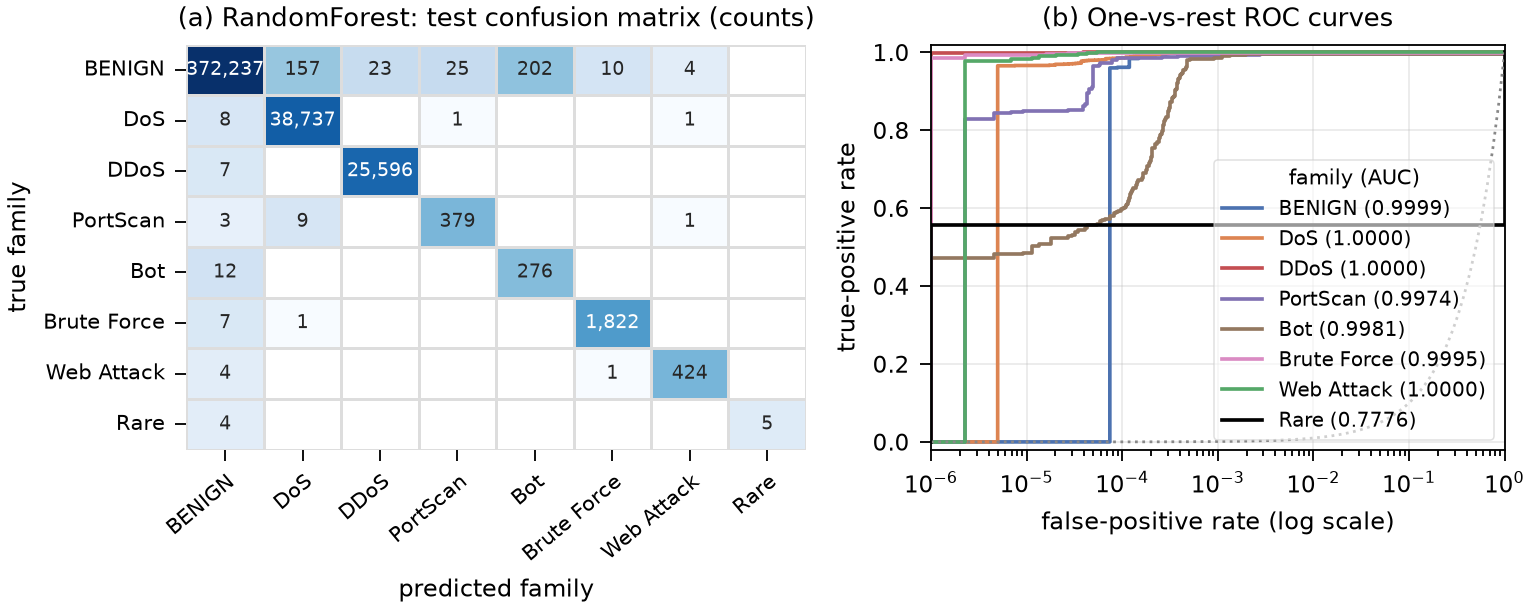

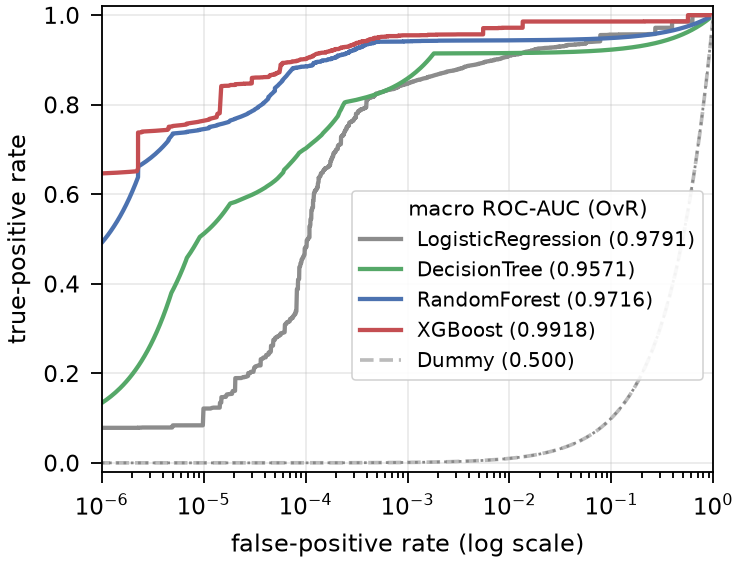

In [23]:
from IPython.display import Image
diag = pipeline.stage_diagnostics(train, test, FEATURES, tuned, fitted, tune_df, cv_folds, tune_summary,
                                  raw_counts, results=results, force=FORCE_RECOMPUTE)
print("saved best model predicts like the refit:", diag["best_model_same_predictions"])
display(diag["baseline"])
display(diag["roc_auc_per_class"])
display(Image(filename=str(config.FIGURES_DIR / "18_final_model_cm_roc.png")))
display(Image(filename=str(config.FIGURES_DIR / "19_roc_comparison.png")))

**Observations**

- The refitted models reproduce the stored test metrics exactly, and the saved best model predicts the same class for
  every test flow as the refit.
- Balanced accuracy equals macro recall for every model (Random Forest 0.9329), as it should for a multi-class problem.
  The majority-class baseline reaches 0.847 accuracy but only 0.125 balanced accuracy, 0.115 macro F1 and ROC-AUC 0.5,
  which shows how little accuracy says on this data.
- On one-vs-rest ROC-AUC (macro) XGBoost leads with 0.992, then Logistic Regression 0.979, Random Forest 0.972 and
  Decision Tree 0.957. For Random Forest every family except Rare has AUC of at least 0.997; four of the nine Rare test
  flows get a Rare probability of zero, which caps its Rare AUC at 0.778. With only nine positives the Rare curve is
  noisy and moves in steps of 1/9.
- The ranking by AUC differs from the ranking by macro F1 because AUC judges how well the probabilities order the flows
  at every threshold, while macro F1 judges the actual predicted classes.

## 9.2 Over- and underfitting

We carve a stratified 20% validation slice out of the **training** split (seed 42; the test split is not used), fit
every tuned model on the other 80% and compare training and validation macro F1. Our rule: training macro F1 below
0.90 means **underfitting** (high bias); otherwise a train-validation gap above 0.05 means **overfitting** (high
variance), a gap between 0.02 and 0.05 a slight overfit, and a smaller gap a good fit.

Learning curves (Logistic Regression and Random Forest) and validation curves (Decision Tree depth, XGBoost boosting
rounds) use a 200k-row stratified training subsample that keeps every minority row, with 3-fold StratifiedKFold.

,cv5_f1_macro_mean,cv5_f1_macro_std,cv5_balanced_accuracy,train_f1_macro,cv3_tuned_f1_macro
model,,,,,
LogisticRegression,0.5336,0.0021,0.9536,0.7232,0.7899
DecisionTree,0.9448,0.0176,0.9374,0.9792,0.9494
RandomForest,0.9536,0.0124,0.9543,0.9635,0.9630
XGBoost,0.9599,0.0069,0.9690,0.9670,0.9660
Dummy,0.1136,0.0000,0.1250,0.1146,NaN


,model,fit_rows,val_rows,train_f1_macro,val_f1_macro,gap,diagnosis
0,LogisticRegression,1407859,351965,0.7204,0.7164,0.0041,underfit (high bias)
1,DecisionTree,1407859,351965,0.9733,0.9181,0.0553,overfit (high variance)
2,RandomForest,1407859,351965,0.9651,0.9477,0.0173,good fit
3,XGBoost,1407859,351965,0.9706,0.9441,0.0264,slight overfit
4,Dummy,1407859,351965,0.1146,0.1146,0.0000,underfit (high bias)


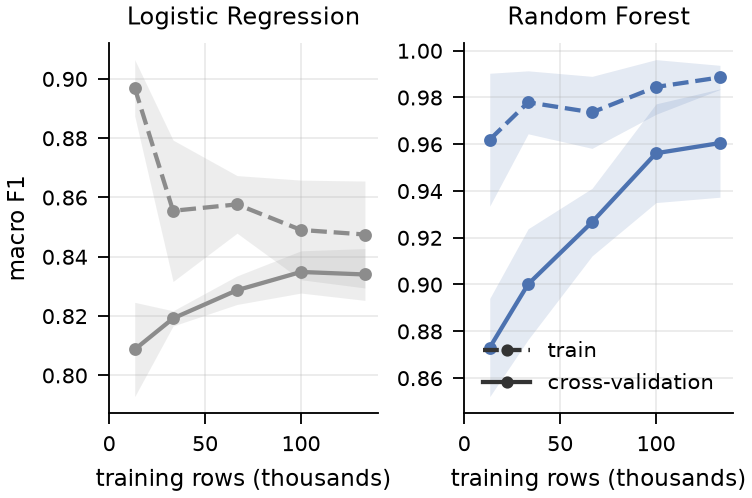

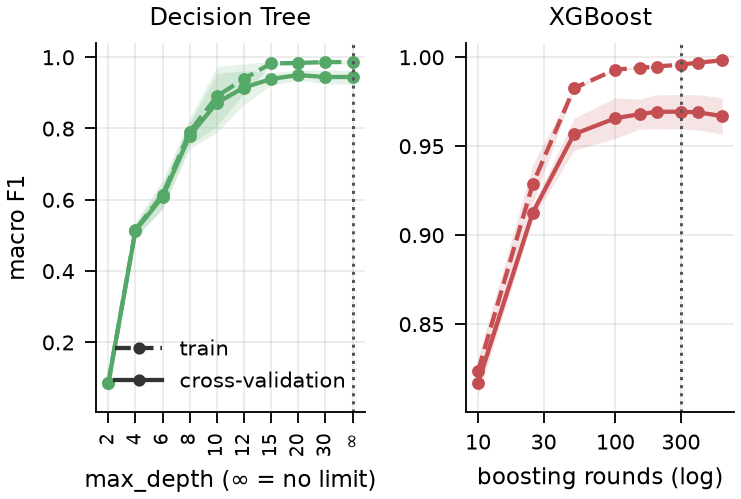

In [24]:
display(diag["cv_overview"])
display(diag["fit_diagnosis"])
display(Image(filename=str(config.FIGURES_DIR / "20_learning_curves.png")))
display(Image(filename=str(config.FIGURES_DIR / "21_validation_curves.png")))

**Observations**

- On the validation slice carved from the training split, Logistic Regression scores 0.720 on its own rows and 0.716 on
  new rows: almost no gap, but too low, so it underfits (high bias). The Decision Tree drops from 0.973 to 0.918 (gap
  0.055, overfit), XGBoost from 0.971 to 0.944 (gap 0.026, slight overfit) and Random Forest from 0.965 to 0.948 (gap
  0.017, good fit). The validation ranking (Random Forest, XGBoost, Decision Tree, Logistic Regression) matches the test
  ranking.
- The learning curves show the same picture. Logistic Regression's training and CV scores meet at about 0.84 and stop
  improving, so more data would not help. Random Forest's CV score keeps rising, from 0.873 at 13k rows to 0.960 at 133k
  rows, while its gap to the training score shrinks from 0.089 to 0.028.
- The Decision Tree validation curve moves from underfitting (0.086 at depth 2) to overfitting: beyond depth 15 the
  training score reaches 0.98-0.99 while CV stays at 0.94-0.95. XGBoost's CV score peaks at 0.969 around 200-300 rounds
  and slips to 0.967 at 600 rounds while the training score keeps rising, so the tuned 300 rounds sit near the best point.

## 10. Attack patterns: what distinguishes each attack?

We study attack differences from three viewpoints: global model-native importance, per-family SHAP values and effect
directions from the best model on a stratified test subsample, and raw feature distributions for each family.

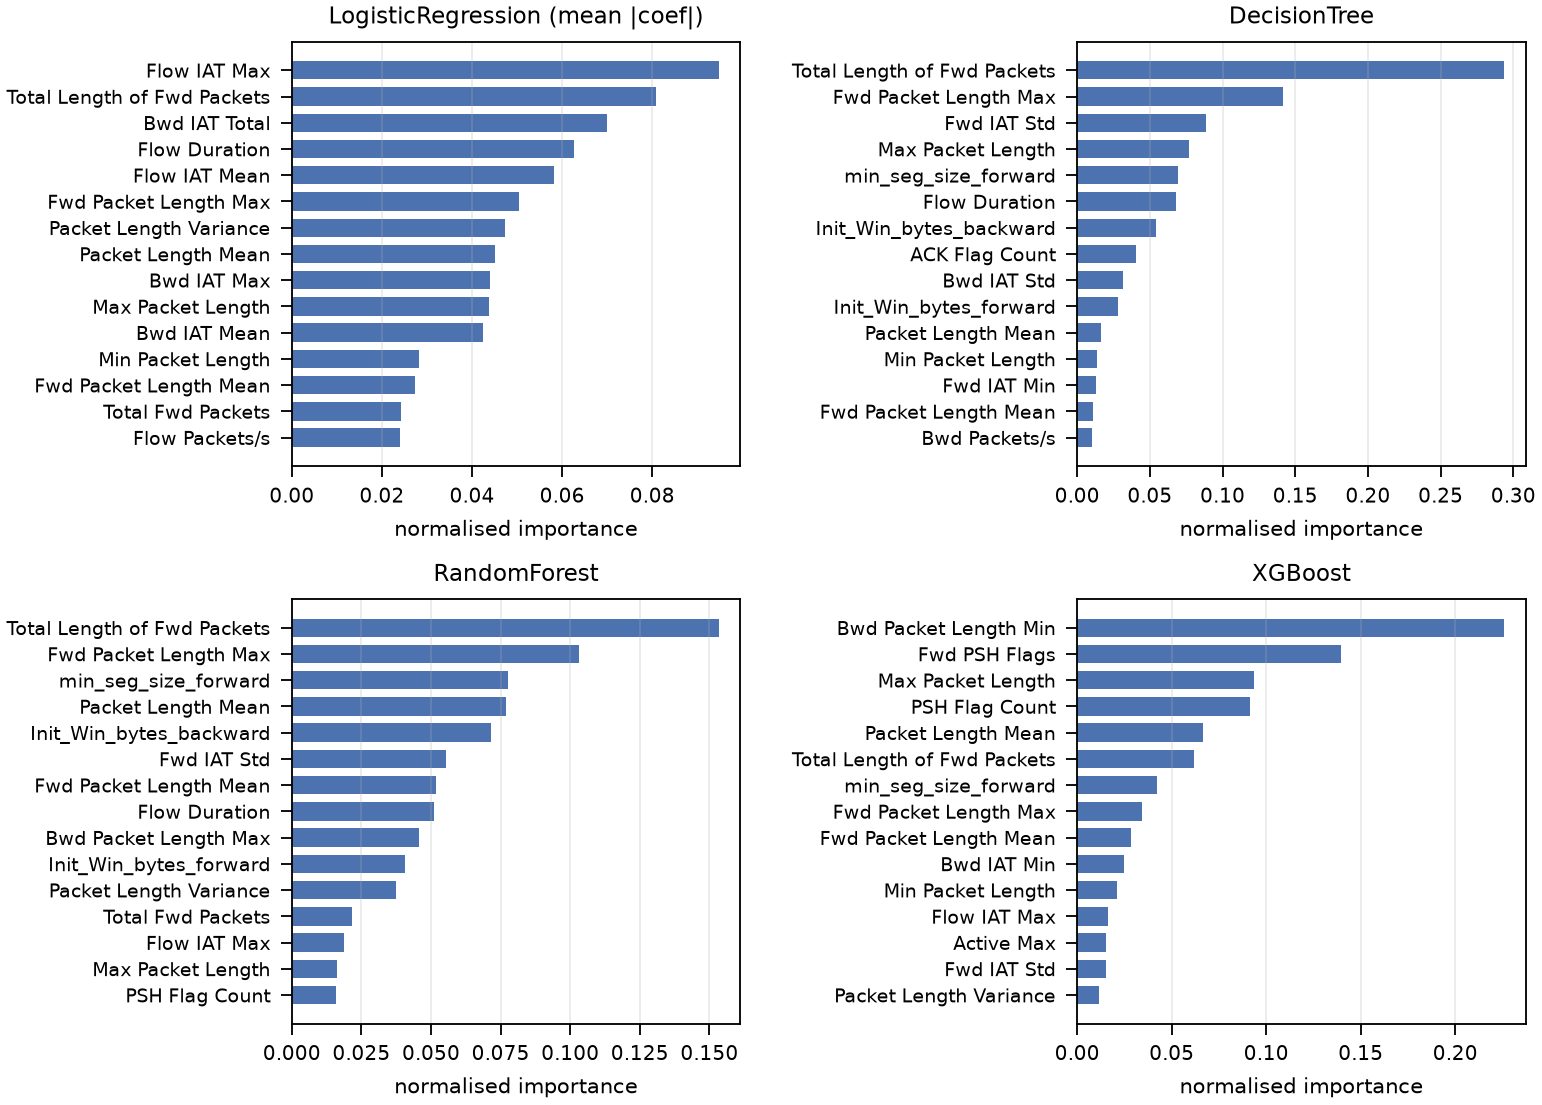

In [25]:
exp = pipeline.stage_explain(best, fitted, train, test, FEATURES)
from IPython.display import Image
display(Image(filename=str(config.FIGURES_DIR / "12_feature_importance.png")))

**Observations**

- Across tree models, **payload size** features rank first (`Total Length of Fwd Packets`, `Fwd Packet Length Max`,
  `Packet Length Mean`), followed by **TCP handshake** features (`min_seg_size_forward`,
  `Init_Win_bytes_backward/forward`) and forward inter-arrival variation (`Fwd IAT Std`).
- XGBoost gain gives more weight to `Bwd Packet Length Min`, `Fwd PSH Flags` and `PSH Flag Count`, which are correlated
  views of packet-size and flag behaviour. Alongside payload size, Logistic Regression depends more on timing
  (`Flow IAT Max`, `Bwd IAT Total`, `Flow Duration`, `Flow IAT Mean`) because log-scaled times provide its clearest
  linear separation.

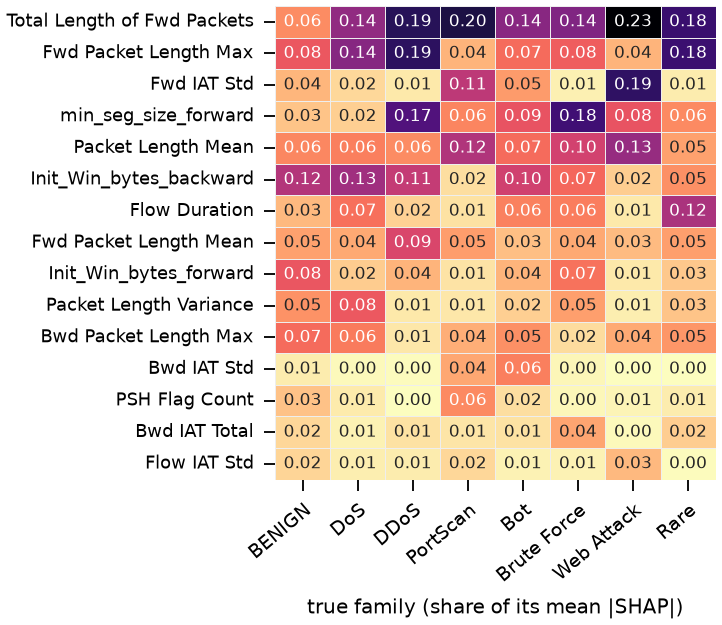

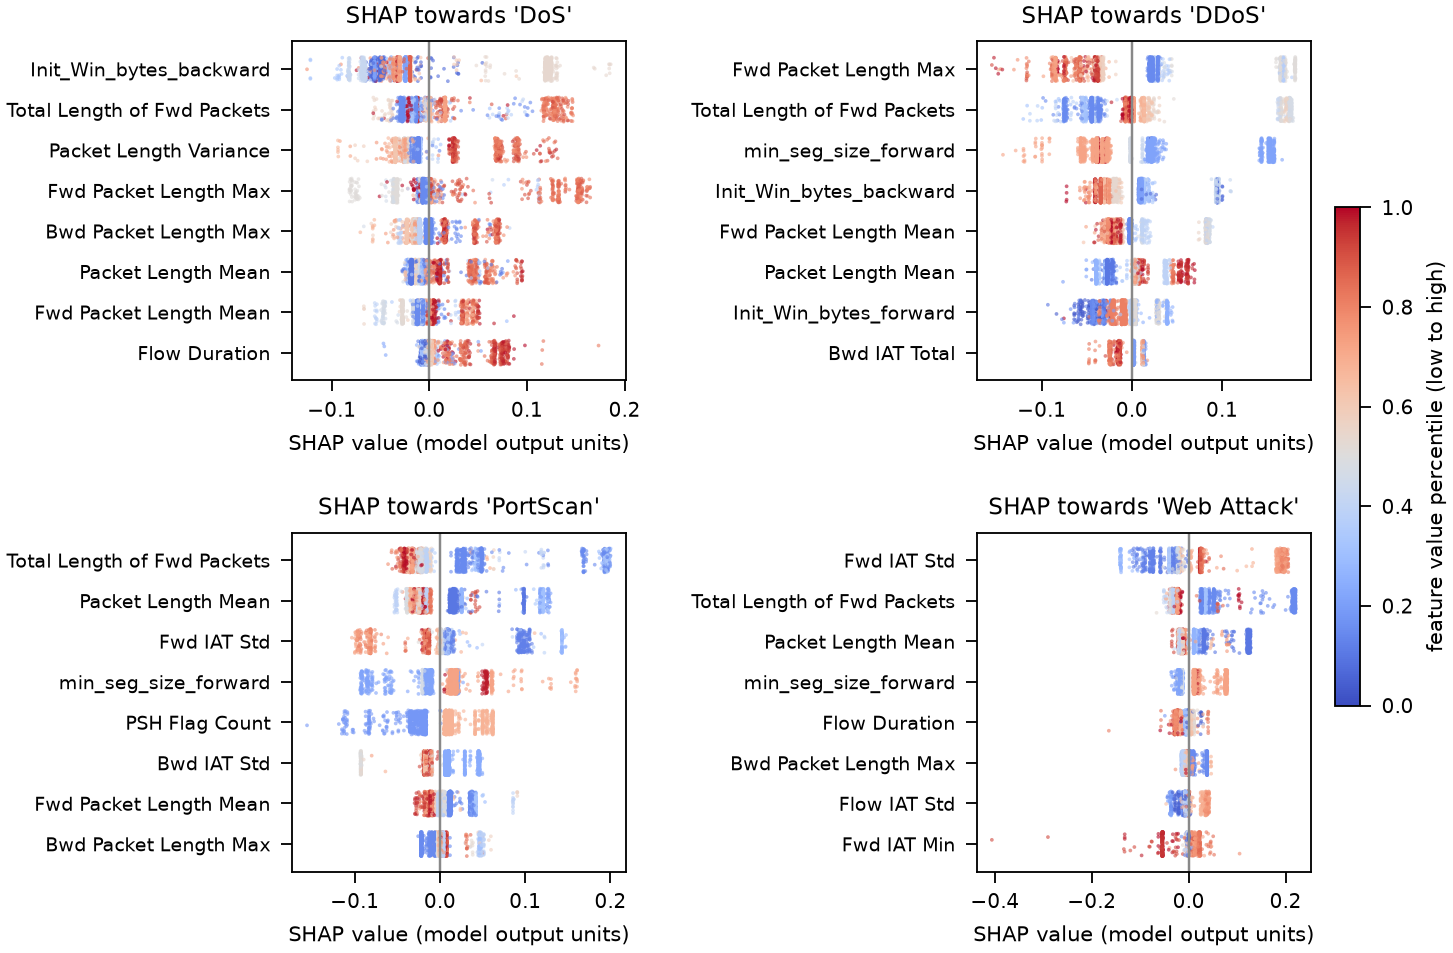

In [26]:
display(Image(filename=str(config.FIGURES_DIR / "13_shap_by_family.png")))
display(Image(filename=str(config.FIGURES_DIR / "14_shap_beeswarm.png")))

**Observations**

- SHAP results for Random Forest use 1,759 stratified test flows, up to 250 per family, and show a separate signature
  for each family in Figure 13. DDoS is associated with small forward packets (`Total Length of Fwd Packets`,
  `Fwd Packet Length Max`) and `min_seg_size_forward`; PortScan with zero payload plus low `Packet Length Mean` and
  `Fwd IAT Std`; Web Attack with `Total Length of Fwd Packets` and high `Fwd IAT Std`; Brute Force with
  `min_seg_size_forward` from the tool's TCP options; DoS with large forward packets and `Init_Win_bytes_backward`;
  and Rare with very large payloads and long `Flow Duration`.
- Figure 14's beeswarms show effect direction. High forward payload and long duration move predictions toward DoS;
  *low* forward packet sizes toward DDoS; zero payload with regular timing toward PortScan; and little payload with
  irregular forward timing, represented by high `Fwd IAT Std`, toward Web Attack.

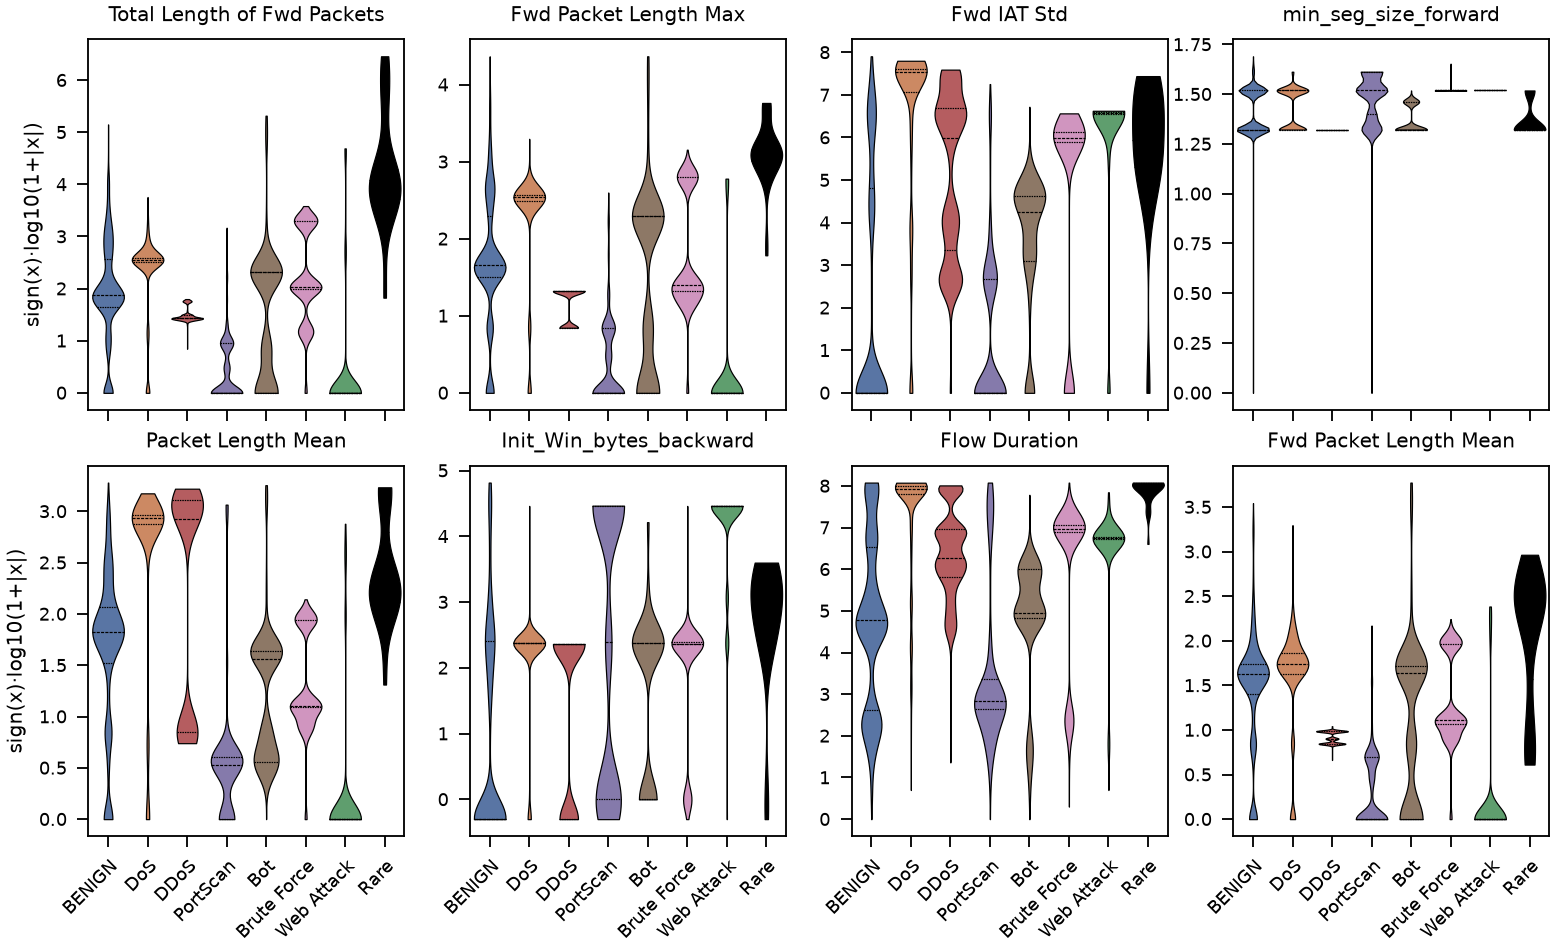

,family,feature,family_median,benign_median,pattern
0,DoS,Fwd Packet Length Max,343,44,median is much higher than benign
1,DoS,Total Length of Fwd Packets,354,74,median is much higher than benign
2,DoS,Init_Win_bytes_backward,235,-1,median is higher than benign
3,DDoS,Total Length of Fwd Packets,26,74,median is lower than benign
4,DDoS,Fwd Packet Length Max,20,44,median is lower than benign
5,DDoS,min_seg_size_forward,20,20,median is close to benign
6,PortScan,Total Length of Fwd Packets,0,74,median is much lower than benign
7,PortScan,Packet Length Mean,2.4,66.6,median is much lower than benign
8,PortScan,Fwd IAT Std,0 us,0 us,median is close to benign
9,Bot,Total Length of Fwd Packets,206,74,median is higher than benign


In [27]:
display(Image(filename=str(config.FIGURES_DIR / "15_attack_feature_distributions.png")))
display(exp["signatures"])

**Observations**

- Raw distributions agree with SHAP. A median DoS flow sends 354 forward bytes in packets up to 343 B, compared with
  74 B / 44 B for benign traffic; the median DDoS flow sends only 26 B. PortScan and Web Attack generally send **no**
  forward payload, while Rare sends ~12 kB over ~100 s against a benign median flow of 59 ms.
- Constant `min_seg_size_forward` / `Init_Win_bytes_forward` values make the attack tools' TCP stack a fingerprint for
  Brute Force and Web Attack. This helps within this dataset but may not generalise to different tools (§13).
- Zero-payload Web Attack and PortScan flows correspond to the "TCP teardown" artefacts reported for CIC-IDS2017
  (Engelen et al., 2021), indicating that the models partly learn how CICFlowMeter divided attack connections.

## 11. Dashboard, traffic replay and per-detection explanations (steps 11-14)

`app/streamlit_app.py` loads `models/best_model.joblib`, which combines preprocessing and the model in one pipeline.
The application provides:
* **Overview** - We show predictions for all loaded flows, predicted and true attack frequencies, binary metrics and
  the latest detections.
* **Live replay** - We stream flows in capture-time order with adjustable speed (1x-3600x capture time) and batch size,
  alongside live alert KPIs, a detection timeline and an alert feed.
* **Attack patterns** - We provide interactive Plotly box/scatter plots by family, a detection timeline, confusion
  matrix, model comparison and per-class F1.
* **Explain a detection** - A selected attack displays its predicted class, confidence, class probabilities, leading
  SHAP features and a plain-language reason.

For local use, we run `streamlit run app/streamlit_app.py`. It accepts the committed
`data/sample/cicids2017_sample.csv.gz`, containing 29,999 flows drawn from the **test** split, or an uploaded CSV.
The following cells run the same replay and explanation logic without the interface.

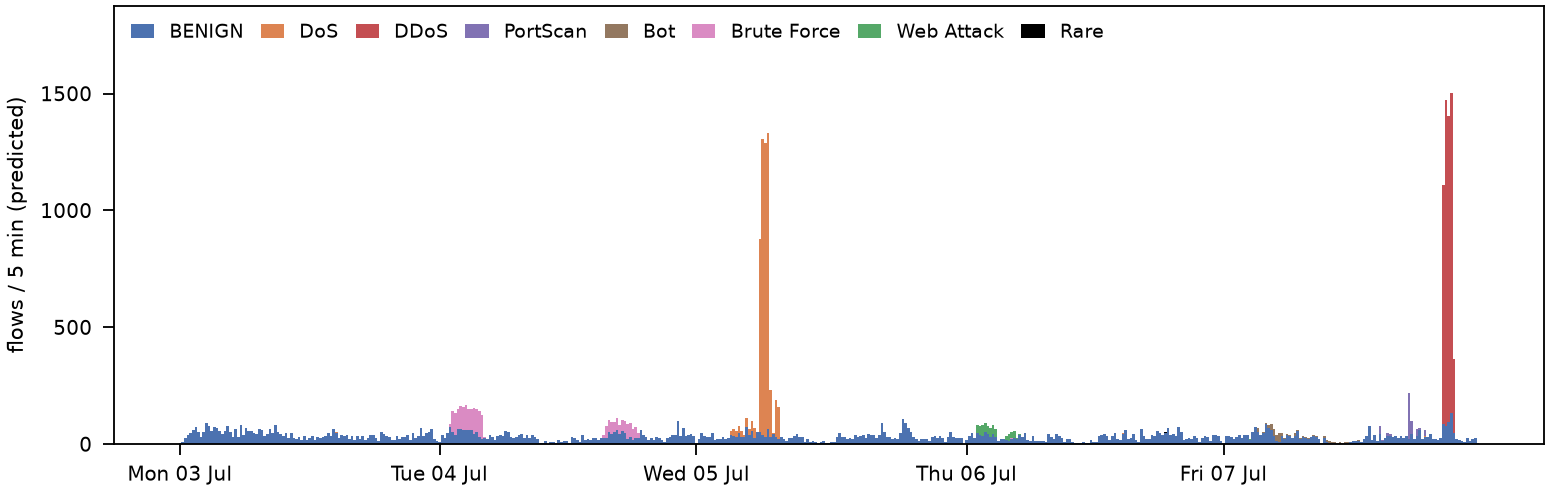

,BENIGN,DoS,DDoS,PortScan,Bot,Brute Force,Web Attack,Rare
family,,,,,,,,
BENIGN,16207,10,0,2,11,0,1,0
DoS,0,5410,0,0,0,0,0,0
DDoS,0,0,5410,0,0,0,0,0
PortScan,3,9,0,379,0,0,1,0
Bot,12,0,0,0,276,0,0,0
Brute Force,7,1,0,0,0,1822,0,0
Web Attack,4,0,0,0,0,1,424,0
Rare,4,0,0,0,0,0,0,5


In [28]:
sample = pd.read_csv(config.SAMPLE_PATH)
sample = replay.order_stream(data.prepare_external(sample))
best_pipe = fitted[best][0]
replayed = pipeline.stage_replay(best_pipe, FEATURES, sample)
display(Image(filename=str(config.FIGURES_DIR / "16_replay_timeline.png")))
display(pd.read_csv(config.RESULTS_DIR / "replay_summary.csv", index_col=0))

**Observations**

- Replaying the 29,999-flow test sample in capture order reconstructs Figure 2's schedule: Brute Force on Tuesday,
  the Wednesday-morning DoS burst, Thursday-morning web attacks, Friday-morning Bot, then PortScan and DDoS on
  Friday afternoon.
- In this sample, the model passes 16,207 of 16,231 BENIGN flows and detects every DoS and DDoS flow. Its misses match
  the full test split: the same 4 Infiltration and 12 Bot flows become BENIGN, while 13 PortScan flows are mostly
  classified as DoS.
- The paced generator emits 500-flow ticks at 300x capture speed, and the dashboard runs the same code through a
  speed slider.

In [29]:
# Step 12: paced replay generator - first 3 ticks at 300x capture speed.
for step in replay.replay(sample, best_pipe, FEATURES, batch_size=500, speed=300, max_sleep=0.5):
    print(step.index, step.capture_time, f"{step.progress:.1%}", step.batch["predicted"].value_counts().to_dict())
    if step.index == 2:
        break

0 2017-07-03 09:51:45 1.7% {'BENIGN': 500}


1 2017-07-03 10:31:36 3.3% {'BENIGN': 500}


2 2017-07-03 11:17:17 5.0% {'BENIGN': 500}


In [30]:
# Step 14: explain one detection per attack family with SHAP + a plain-language reason.
explainer = explain.make_explainer(best_pipe)
benign_median = explain.family_medians(train, FEATURES).loc[config.BENIGN]
preds = replay.predict_batch(best_pipe, sample, FEATURES)
for fam in ["DoS", "DDoS", "PortScan", "Bot", "Brute Force", "Web Attack", "Rare"]:
    hits = sample.index[(preds["predicted"] == fam) & (sample[config.TARGET_COL] == fam)]
    if len(hits) == 0:
        continue
    res = explain.explain_flow(best_pipe, explainer, sample.loc[[hits[0]]], FEATURES, benign_median, top_k=5)
    display(Markdown(f"**{fam}** (true label: {sample.loc[hits[0], config.RAW_LABEL_COL]}) - {res['reason']}"))
    display(res["contributions"])

**DoS** (true label: DoS slowloris) - Flagged as **DoS** with 100% confidence. Main evidence: Init_Win_bytes_backward = 235 is higher than typical benign traffic (-1); Total Length of Fwd Packets = 231 is much higher than typical benign traffic (74); Fwd Packet Length Max = 231 is much higher than typical benign traffic (44).

,feature,value,benign_median,shap
0,Init_Win_bytes_backward,235.0000,-1.0000,0.1332
1,Total Length of Fwd Packets,231.0000,74.0000,0.1194
2,Fwd Packet Length Max,231.0000,44.0000,0.1067
3,Bwd Packet Length Max,0.0000,105.0000,0.0589
4,min_seg_size_forward,32.0000,20.0000,0.0473


**DDoS** (true label: DDoS) - Flagged as **DDoS** with 100% confidence. Main evidence: Total Length of Fwd Packets = 26 is lower than typical benign traffic (74); Fwd Packet Length Max = 20 is lower than typical benign traffic (44); min_seg_size_forward = 20 is close to typical benign traffic (20).

,feature,value,benign_median,shap
0,Total Length of Fwd Packets,26.0000,74.0000,0.1748
1,Fwd Packet Length Max,20.0000,44.0000,0.1650
2,min_seg_size_forward,20.0000,20.0000,0.1535
3,Init_Win_bytes_backward,229.0000,-1.0000,0.0944
4,Fwd Packet Length Mean,8.6667,41.0000,0.0817


**PortScan** (true label: PortScan) - Flagged as **PortScan** with 97% confidence. Main evidence: Total Length of Fwd Packets = 2 is much lower than typical benign traffic (74); Packet Length Mean = 3.33 is much lower than typical benign traffic (66.6); Fwd IAT Std = 0 us is close to typical benign traffic (0 us).

,feature,value,benign_median,shap
0,Total Length of Fwd Packets,2.0000,74.0000,0.1988
1,Packet Length Mean,3.3333,66.6000,0.1218
2,Fwd IAT Std,0.0000,0.0000,0.1004
3,PSH Flag Count,1.0000,0.0000,0.0605
4,Bwd Packet Length Max,6.0000,105.0000,0.0476


... (4 outputs left out)

**Web Attack** (true label: Web Attack - Brute Force) - Flagged as **Web Attack** with 95% confidence. Main evidence: Total Length of Fwd Packets = 0 is much lower than typical benign traffic (74); Fwd IAT Std = 2.86 s is higher than typical benign traffic (0 us); Packet Length Mean = 0 is much lower than typical benign traffic (66.6).

,feature,value,benign_median,shap
0,Total Length of Fwd Packets,0.0000,74.0000,0.1740
1,Fwd IAT Std,2863098.0000,0.0000,0.1308
2,Packet Length Mean,0.0000,66.6000,0.0843
3,Bwd Packets/s,0.2469,22.4927,0.0720
4,min_seg_size_forward,32.0000,20.0000,0.0623


**Rare** (true label: Heartbleed) - Flagged as **Rare** with 100% confidence. Main evidence: Total Length of Fwd Packets = 13,712 is much higher than typical benign traffic (74); Fwd Packet Length Max = 5,792 is much higher than typical benign traffic (44); Flow Duration = 119.26 s is much higher than typical benign traffic (58.6 ms).

,feature,value,benign_median,shap
0,Total Length of Fwd Packets,13712.0000,74.0000,0.1803
1,Fwd Packet Length Max,5792.0000,44.0000,0.1282
2,Flow Duration,119262216.0000,58563.5000,0.0912
3,Packet Length Mean,1610.7769,66.6000,0.0645
4,Packet Length Variance,5827835.0000,1240.3334,0.0593


**Observations**

- For each flow, our explanation reports the predicted family, probability and the features moving the prediction away
  from the typical median benign value. The DoS example has forward packets ~5x larger than normal and a server TCP
  window (`Init_Win_bytes_backward` = 235) where most benign flows have none. The PortScan example carries only
  2 bytes of payload, while the Rare Heartbleed example transfers 13.7 kB over 119 s.
- The dashboard's "Explain a detection" tab presents these same per-detection explanations with a SHAP bar chart and
  class probabilities.

## 12. Reproducibility

* We can reproduce the full workflow with `python -m cyberreplay.pipeline --download`; `--force` recomputes tuning
  and fitting, while `--quick` runs a smoke test.
* `requirements.txt` pins dependencies, and every split, sample, model and search uses seed 42.
* We save the final feature selection + imputation + model pipeline as `models/best_model.joblib`, together with
  `best_model_metadata.json` containing features, parameters, test metrics and library versions.
* We run unit tests and a headless dashboard test with `pytest tests`.
* We store all figures in `reports/figures` and all tables in `reports/results`.

In [31]:
import platform, sklearn, xgboost, shap
print("python", platform.python_version(), "| sklearn", sklearn.__version__, "| xgboost", xgboost.__version__,
      "| shap", shap.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)
print(utils.load_json(config.MODEL_METADATA_PATH)["justification"])

python 3.12.3 | sklearn 1.9.1 | xgboost 3.4.1 | shap 0.54.1 | pandas 3.1.1 | numpy 2.5.5
RandomForest has macro F1 0.9206 (next best 0.9117), minority-class recall 0.8929, BENIGN false-positive rate 0.1130%, trains in 104s and predicts at 1.23 us/flow.


## 13. Conclusions, limitations and future work

**Conclusions.** After removing 631k duplicate CIC-IDS2017 flows and every identifier, we trained a class-weighted Random
Forest on 37 selected flow features. It classifies 8 attack families at test macro F1 **0.921** (0.950 without the 9-flow
Rare class), detects 99.9% of malicious flows with a 0.11% false-alarm rate, and predicts each flow in about a microsecond.
XGBoost follows closely in the statistical comparison, while Decision Tree is nearly as accurate and has the fastest
inference. Logistic Regression is not sufficient for these non-linear families (macro F1 0.715, 15x more false alarms).
We found that payload size, TCP handshake parameters and forward timing separate the attacks; SHAP explains individual
alerts, and the replay dashboard demonstrates the model as an interactive monitoring prototype.

**Limitations.**
- *Optimistic split:* Our random stratified split places flows from one attack burst in both train and test. GroupKFold by
  day cannot solve this because each attack appears on one day, so the scores show recognition of known attacks within
  the same network rather than generalisation to new networks or attack tools.
- *Label quality:* CIC-IDS2017 contains documented labelling and flow-construction errors (Engelen et al., 2021). Most Bot
  "false positives" contact the Ares C&C server and are probably unlabelled bot traffic, while zero-payload
  Web Attack/PortScan flows partly reflect TCP-teardown artefacts.
- *Tiny classes:* Rare contains 47 flows (9 in test), giving its F1 a very wide confidence interval, and Infiltration
  recall remains low.
- *Tool fingerprints:* Features such as `Init_Win_bytes_*` and `min_seg_size_forward` identify the attack tools' TCP
  stacks and may not transfer to other tools.
- *Offline features:* CICFlowMeter calculates features only when a flow ends. The replay is therefore near-real-time
  rather than packet-level real-time, and timestamps have only minute resolution except Monday.

**Future work.** We would test per-class probability thresholds or cost-sensitive calibration to reduce the remaining
Bot/DoS false alarms; evaluate corrected CIC-IDS2017 labels and run cross-dataset tests such as CSE-CIC-IDS2018 to measure
generalisation; use time-aware validation within each attack day; compute streaming flow features for true online
detection; and add anomaly detection for unseen (zero-day) attacks that a supervised classifier cannot recognise.

**References.** Sharafaldin, Lashkari & Ghorbani, ICISSP 2018 (dataset); Engelen, Rimmer & Joosen, "Troubleshooting an
Intrusion Detection Dataset: the CICIDS2017 Case Study", IEEE S&P Workshops 2021; Pedregosa et al., JMLR 2011
(scikit-learn); Chen & Guestrin, KDD 2016 (XGBoost); Lundberg & Lee, NeurIPS 2017 and Lundberg et al., Nature Machine
Intelligence 2020 (SHAP).